1 – Project Introduction

In [1]:
# MINI DATA SCIENCE PROJECT
# Project: Titanic Survival Analysis and Prediction
#
# Problem Statement:
# Analyze Titanic passenger data to identify factors affecting
# survival and build a basic model to predict passenger survival.
#
# Objective:
# Perform data loading, cleaning, EDA, visualization,
# statistical analysis and machine learning.

2 – Import Libraries

In [2]:
# Import libraries required for data analysis and ML

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


3 – Load Dataset

In [3]:
# Load Titanic dataset from an online CSV source

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


4 – Dataset Overview

In [4]:
# Explore the dataset structure and columns

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


5 – Data Cleaning

In [5]:
# Remove duplicate records and unnecessary columns

df = df.drop_duplicates()

# Cabin has a large number of missing values
df = df.drop(columns=["Cabin"])

# Fill missing numerical values using median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing categorical values using mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Data cleaning completed!")

print("\nMissing Values:")
print(df.isnull().sum())

Data cleaning completed!

Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


6 – Statistical Analysis

In [6]:
# Calculate basic statistical information

print("Total Passengers:", len(df))
print("Average Age:", round(df["Age"].mean(), 2))
print("Median Age:", round(df["Age"].median(), 2))
print("Average Fare:", round(df["Fare"].mean(), 2))
print("Overall Survival Rate:",
      round(df["Survived"].mean() * 100, 2), "%")

print("\nSurvival Count:")
print(df["Survived"].value_counts())

Total Passengers: 891
Average Age: 29.36
Median Age: 28.0
Average Fare: 32.2
Overall Survival Rate: 38.38 %

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64


7 – Gender Analysis

Survival Rate by Gender:


,Survived
Sex,
female,74.203822
male,18.890815


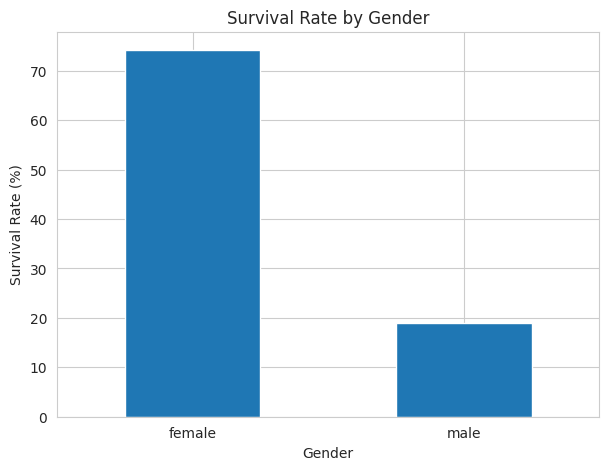

In [7]:
# Analyze passenger survival according to gender

gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival Rate by Gender:")
display(gender_survival)

plt.figure(figsize=(7, 5))
gender_survival.plot(kind="bar")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()

8 – Passenger Class Analysis

Survival Rate by Passenger Class:


,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


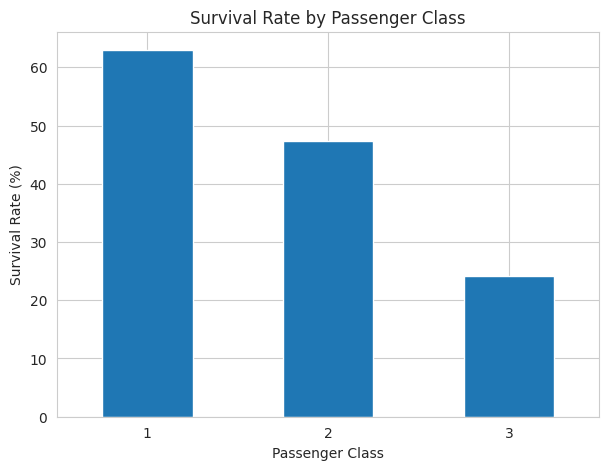

In [8]:
# Analyze survival rate according to passenger class

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class:")
display(class_survival)

plt.figure(figsize=(7, 5))
class_survival.plot(kind="bar")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()

9 – Age Distribution

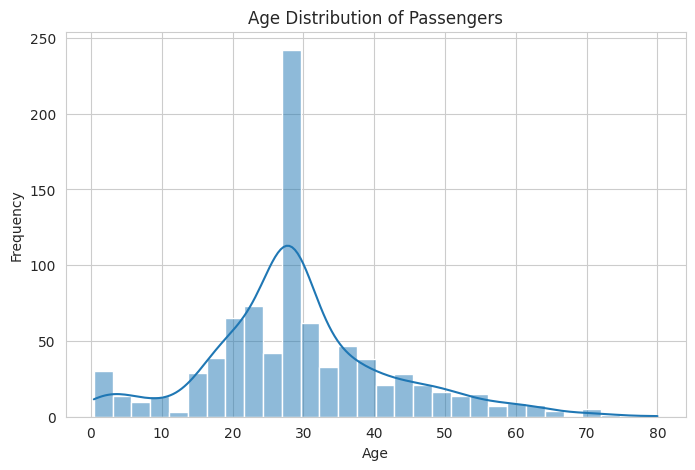

In [9]:
# Visualize the age distribution of passengers

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

10 – Survival Visualization

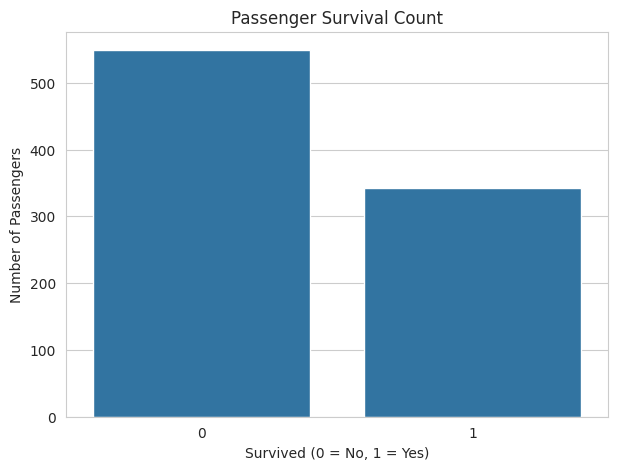

In [10]:
# Compare the number of survived and non-survived passengers

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

11 – Correlation Analysis

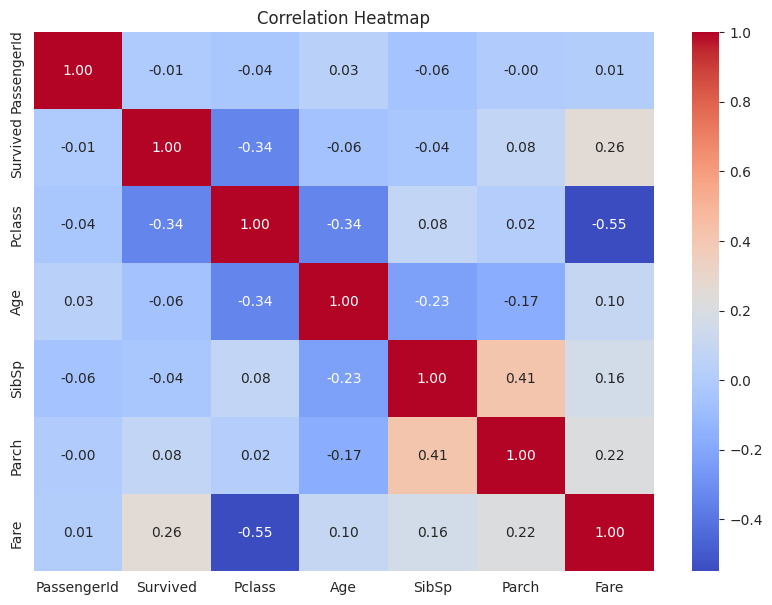

In [11]:
# Analyze correlation between numerical features

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

12 – Family Size Analysis

Survival Rate by Family Size:


,Survived
FamilySize,
1,30.353818
2,55.279503
3,57.843137
4,72.413793
5,20.000000
6,13.636364
7,33.333333
8,0.000000
11,0.000000


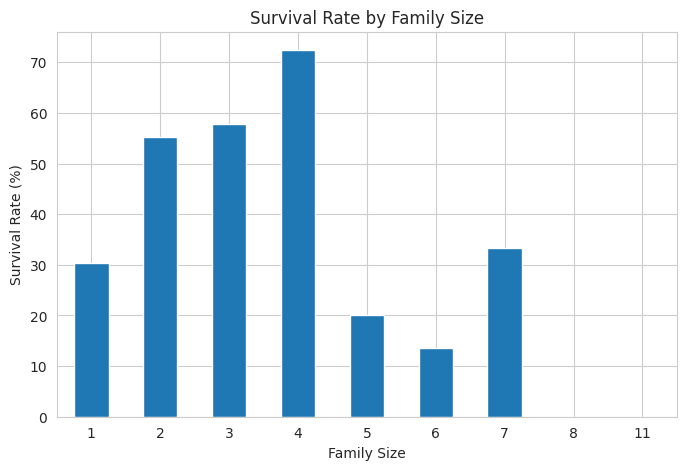

In [12]:
# Create a new feature using family members travelling together

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

family_survival = df.groupby("FamilySize")["Survived"].mean() * 100

print("Survival Rate by Family Size:")
display(family_survival)

plt.figure(figsize=(8, 5))
family_survival.plot(kind="bar")

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()

3 – Prepare Data for Machine Learning

In [13]:
# Select useful features for predicting passenger survival

features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[features]
y = df["Survived"]

# Divide data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (712, 7)
Testing Data Shape: (179, 7)


14 – Build Machine Learning Model

In [14]:
# Prepare numerical and categorical features separately

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create Logistic Regression model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Machine Learning Model trained successfully!")

Machine Learning Model trained successfully!


15 – Model Evaluation

Model Accuracy: 80.45 %

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Confusion Matrix:


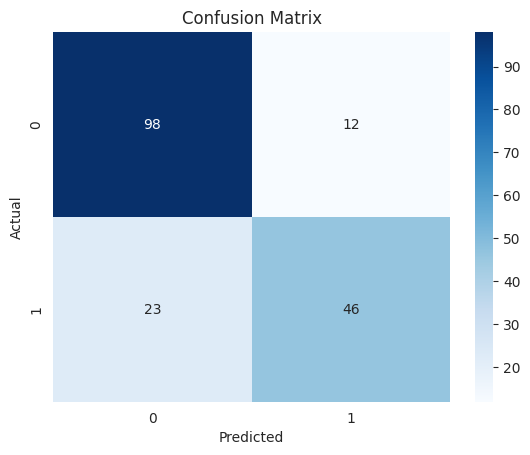

In [15]:
# Predict survival on test data

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

16 – At Least Five Key Findings

In [16]:
# Calculate important findings from the dataset

print("KEY FINDINGS")

print("\n1. Overall Survival Rate:",
      round(df["Survived"].mean() * 100, 2), "%")

print("\n2. Survival Rate by Gender:")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\n3. Survival Rate by Passenger Class:")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\n4. Average Passenger Age:",
      round(df["Age"].mean(), 2))

print("\n5. Survival Rate by Family Size:")
print((df.groupby("FamilySize")["Survived"].mean() * 100).round(2))

print("\n6. Machine Learning Model Accuracy:",
      round(accuracy * 100, 2), "%")

KEY FINDINGS

1. Overall Survival Rate: 38.38 %

2. Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

3. Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

4. Average Passenger Age: 29.36

5. Survival Rate by Family Size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64

6. Machine Learning Model Accuracy: 80.45 %
